# 1. Постановка задачи

## Бизнес-задача
Компания хочет **снизить отток клиентов (churn)**, так как удержание существующих клиентов дешевле, чем привлечение новых.
Нужно **реализовать детектор ухода клиента / не ухода клиента**, чтобы заранее применять меры удержания: персонализированные предложения, скидки, бонусы или улучшение тарифа.
Реализация этой задачи позволит **уменьшить финансовые потери и повысить прибыль компании**.

## ML-задача
Задача формулируется как бинарная классификация:
- 1 — клиент уйдет (Churn = Yes)
- 0 — клиент останется (Churn = No)

## Данные
Данные взяты с Kaggle: [Telco Customer Churn](https://www.kaggle.com/datasets/abdallahwagih/telco-customer-churn).
Датасет содержит информацию примерно о 7000 клиентах и включает:
- демографические характеристики (пол, наличие партнера, возраст и др.)
- информацию об услугах (интернет, телефон и др.)
- финансовые показатели (ежемесячные платежи, общий платеж)

Целевая переменная: Churn.

## Обоснование выбора метрик
Для данной задачи критично правильно выявлять клиентов, которые собираются уйти:
- *False Negative* — клиент уйдет, а мы не предсказали это → потеря прибыли
- *False Positive* — система считает, что клиент уйдет, но он не ушел → излишние затраты на удержание

Выбраны метрики **Recall и F1-score**:
- **Recall** позволяет максимально «поймать» уходящих клиентов
- **F1-score** балансирует между полнотой и точностью, учитывая дисбаланс классов

В моей задаче важно не пропустить клиентов, которые уйдут, поэтому основной метрикой выбрали **Recall**.
Чтобы учитывать и точность предсказаний, используем **F1-score**, что помогает работать с дисбалансом классов, как советуется в статье на Хабре

Импорты и настройка окружения

In [49]:
# Импорт библиотек
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import plotly.express as px

import phik  # для phi-k корреляции
from matplotlib.cbook import boxplot_stats  # для анализа выбросов
from sklearn.preprocessing import StandardScaler  # для масштабирования
from sklearn.decomposition import PCA  # для PCA
import sweetviz as sv  # для автоматического EDA
import warnings
warnings.filterwarnings('ignore')

# Для отображения графиков прямо в ноутбуке
%matplotlib inline
sns.set_theme(style="whitegrid")

In [50]:

# Загрузка данных
import pandas as pd

df = pd.read_excel("../data/Telco_customer_churn.xlsx")

# Размер датасета
print("Shape:", df.shape)

# Первые строки
df.head()

Shape: (7043, 33)


,CustomerID,Count,Country,State,City,Zip Code,Lat Long,Latitude,Longitude,Gender,...,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Label,Churn Value,Churn Score,CLTV,Churn Reason
0,3668-QPYBK,1,United States,California,Los Angeles,90003,"33.964131, -118.272783",33.964131,-118.272783,Male,...,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,1,86,3239,Competitor made better offer
1,9237-HQITU,1,United States,California,Los Angeles,90005,"34.059281, -118.30742",34.059281,-118.307420,Female,...,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,1,67,2701,Moved
2,9305-CDSKC,1,United States,California,Los Angeles,90006,"34.048013, -118.293953",34.048013,-118.293953,Female,...,Month-to-month,Yes,Electronic check,99.65,820.5,Yes,1,86,5372,Moved
3,7892-POOKP,1,United States,California,Los Angeles,90010,"34.062125, -118.315709",34.062125,-118.315709,Female,...,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes,1,84,5003,Moved
4,0280-XJGEX,1,United States,California,Los Angeles,90015,"34.039224, -118.266293",34.039224,-118.266293,Male,...,Month-to-month,Yes,Bank transfer (automatic),103.70,5036.3,Yes,1,89,5340,Competitor had better devices


In [10]:
# Информация о датасете
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 33 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   CustomerID         7043 non-null   object 
 1   Count              7043 non-null   int64  
 2   Country            7043 non-null   object 
 3   State              7043 non-null   object 
 4   City               7043 non-null   object 
 5   Zip Code           7043 non-null   int64  
 6   Lat Long           7043 non-null   object 
 7   Latitude           7043 non-null   float64
 8   Longitude          7043 non-null   float64
 9   Gender             7043 non-null   object 
 10  Senior Citizen     7043 non-null   object 
 11  Partner            7043 non-null   object 
 12  Dependents         7043 non-null   object 
 13  Tenure Months      7043 non-null   int64  
 14  Phone Service      7043 non-null   object 
 15  Multiple Lines     7043 non-null   object 
 16  Internet Service   7043 

In [11]:

# Проверка пропусков
df.isna().sum()

CustomerID              0
Count                   0
Country                 0
State                   0
City                    0
Zip Code                0
Lat Long                0
Latitude                0
Longitude               0
Gender                  0
Senior Citizen          0
Partner                 0
Dependents              0
Tenure Months           0
Phone Service           0
Multiple Lines          0
Internet Service        0
Online Security         0
Online Backup           0
Device Protection       0
Tech Support            0
Streaming TV            0
Streaming Movies        0
Contract                0
Paperless Billing       0
Payment Method          0
Monthly Charges         0
Total Charges           0
Churn Label             0
Churn Value             0
Churn Score             0
CLTV                    0
Churn Reason         5174
dtype: int64

In [7]:

# Базовая статистика по числовым признакам
df.describe()

,Count,Zip Code,Latitude,Longitude,Tenure Months,Monthly Charges,Churn Value,Churn Score,CLTV
count,7043.0,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000
mean,1.0,93521.964646,36.282441,-119.798880,32.371149,64.761692,0.265370,58.699418,4400.295755
std,0.0,1865.794555,2.455723,2.157889,24.559481,30.090047,0.441561,21.525131,1183.057152
min,1.0,90001.000000,32.555828,-124.301372,0.000000,18.250000,0.000000,5.000000,2003.000000
25%,1.0,92102.000000,34.030915,-121.815412,9.000000,35.500000,0.000000,40.000000,3469.000000
50%,1.0,93552.000000,36.391777,-119.730885,29.000000,70.350000,0.000000,61.000000,4527.000000
75%,1.0,95351.000000,38.224869,-118.043237,55.000000,89.850000,1.000000,75.000000,5380.500000
max,1.0,96161.000000,41.962127,-114.192901,72.000000,118.750000,1.000000,100.000000,6500.000000


## Вывод по первичному анализу данных

В ходе первичного анализа датасета было установлено, что он содержит 7043 наблюдения и 33 признака, что является достаточным объемом для решения задачи бинарной классификации.

В данных представлены различные типы признаков:
- числовые (Tenure Months, Monthly Charges, Total Charges, CLTV и др.)
- категориальные (Gender, Contract, Internet Service и др.)
- географические (Country, City, Latitude, Longitude)

Пропуски в данных практически отсутствуют, за исключением признака **Churn Reason**, где отсутствует большая часть значений. Это объясняется тем, что причина ухода известна только для клиентов, которые действительно ушли.

В процессе анализа выявлены следующие особенности:
- признак **CustomerID** является идентификатором и не несет полезной информации для модели
- признак **Total Charges** имеет тип object, хотя является числовым → требуется преобразование
- признак **Count** не содержит вариативности и не будет полезен для модели
- присутствует несколько признаков, связанных с целевой переменной (**Churn Label, Churn Value, Churn Score**), что требует аккуратного выбора target

Анализ числовых признаков показал:
- значительный разброс значений (например, Monthly Charges и Total Charges)
- наличие клиентов с коротким сроком обслуживания
- потенциальную необходимость нормализации признаков

Таким образом, перед обучением модели необходимо:
- удалить нерелевантные признаки (например, CustomerID, Count)
- преобразовать типы данных (Total Charges)
- закодировать категориальные признаки
- при необходимости масштабировать числовые признаки

В целом датасет является качественным и хорошо подходит для решения задачи предсказания оттока клиентов.Анализ целевой переменной Churn

Анализ целевой переменной

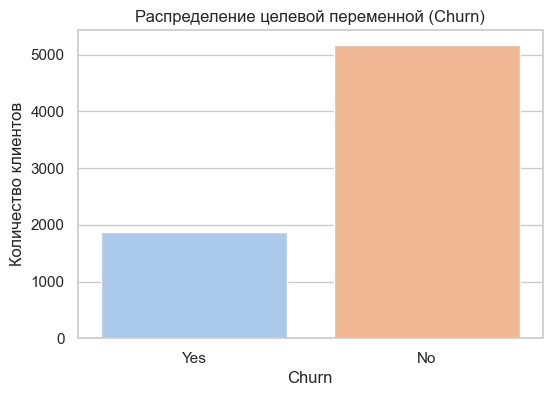

Количество клиентов по классам:
 Churn Label
No     5174
Yes    1869
Name: count, dtype: int64

Доли клиентов по классам:
 Churn Label
No     0.73463
Yes    0.26537
Name: proportion, dtype: float64


In [51]:

# Распределение целевой переменной
plt.figure(figsize=(6,4))
sns.countplot(x='Churn Label', data=df, palette='pastel')
plt.title("Распределение целевой переменной (Churn)")
plt.xlabel("Churn")
plt.ylabel("Количество клиентов")
plt.show()

# Доли классов
churn_counts = df['Churn Label'].value_counts()
churn_ratio = df['Churn Label'].value_counts(normalize=True)

print("Количество клиентов по классам:\n", churn_counts)
print("\nДоли клиентов по классам:\n", churn_ratio)

## Анализ целевой переменной

Целевая переменная — **Churn Label** (ушёл/не ушёл клиент).

Из 7043 клиентов:
- **No** — 5174 (≈73,5%)
- **Yes** — 1869 (≈26,5%)

Видим сильный дисбаланс: большинство клиентов остаются.
Это значит, что обычная точность мало информативна — модель может просто предсказывать "No" и получить ~73% точности.

Поэтому для оценки модели лучше использовать **Recall** (чтобы не пропустить ушедших клиентов) и **F1-score** (чтобы учесть и точность, и полноту).

Анализ категориальных признаков

Категориальные признаки для анализа: ['Country', 'State', 'Gender', 'Senior_Citizen', 'Partner', 'Dependents', 'Phone_Service', 'Multiple_Lines', 'Internet_Service', 'Online_Security', 'Online_Backup', 'Device_Protection', 'Tech_Support', 'Streaming_TV', 'Streaming_Movies', 'Contract', 'Paperless_Billing', 'Payment_Method', 'Total_Charges', 'Churn_Reason']


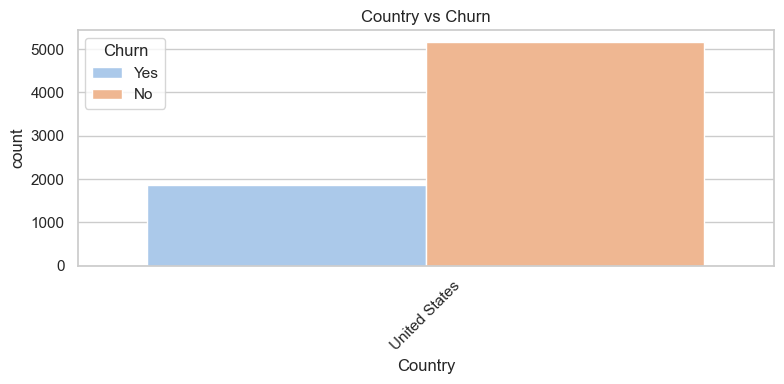

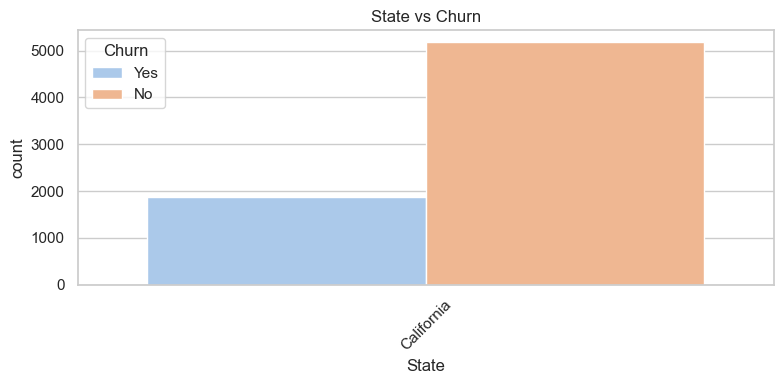

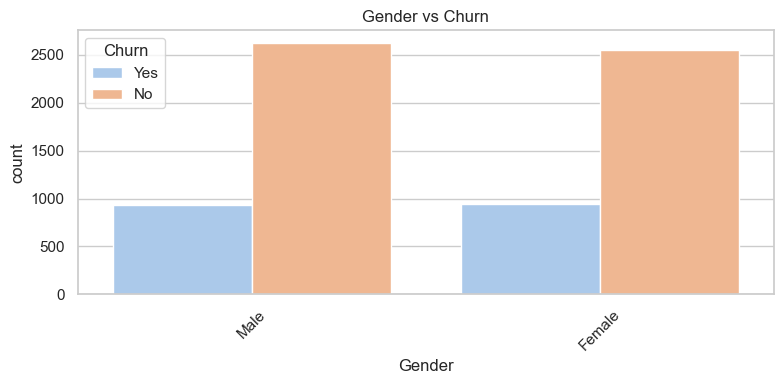

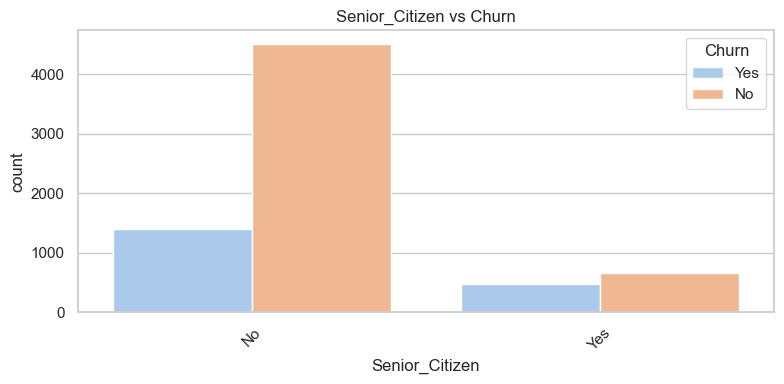

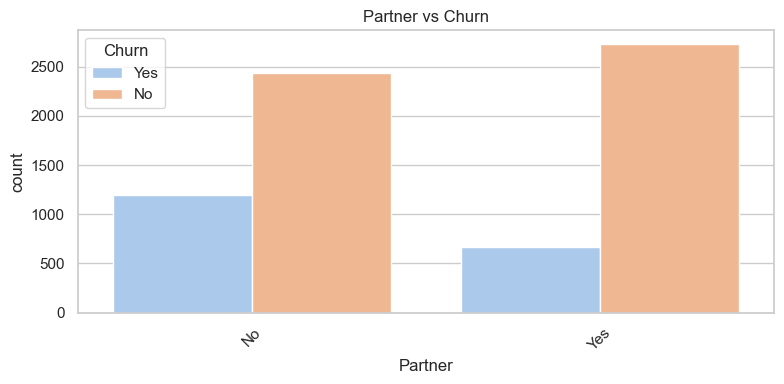

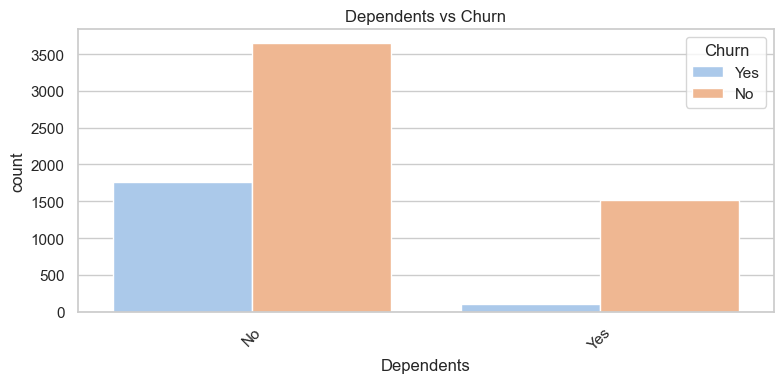

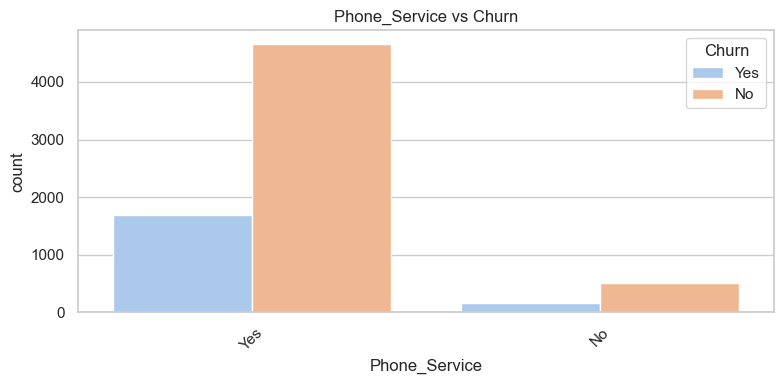

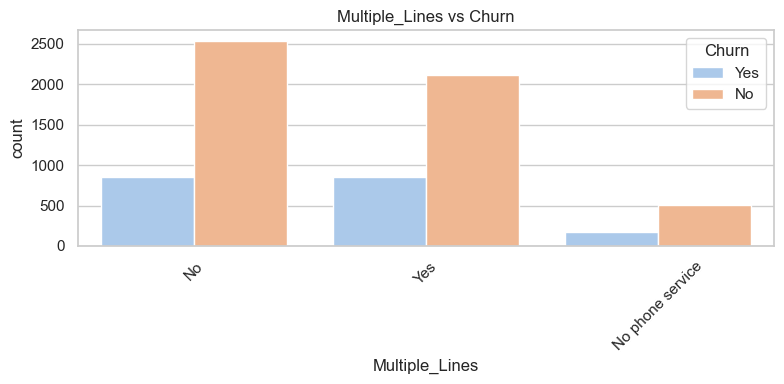

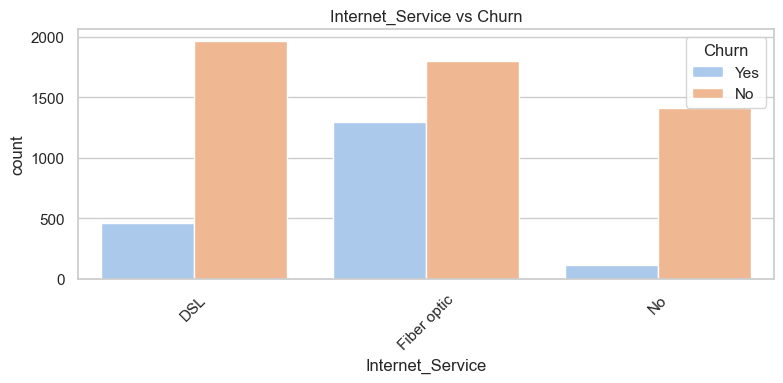

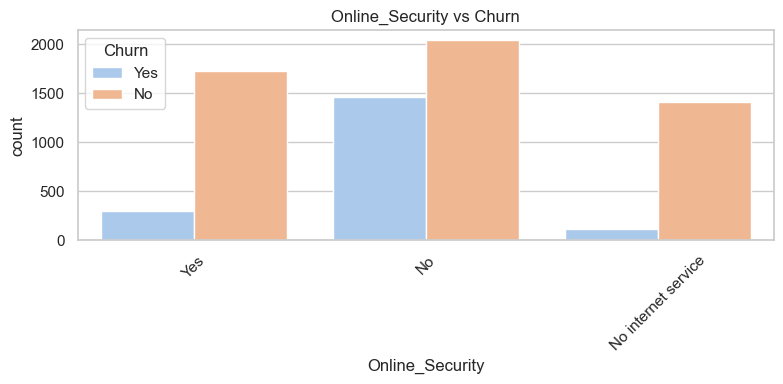

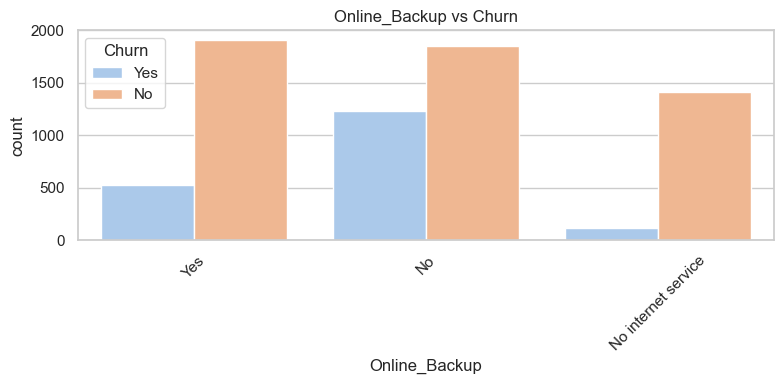

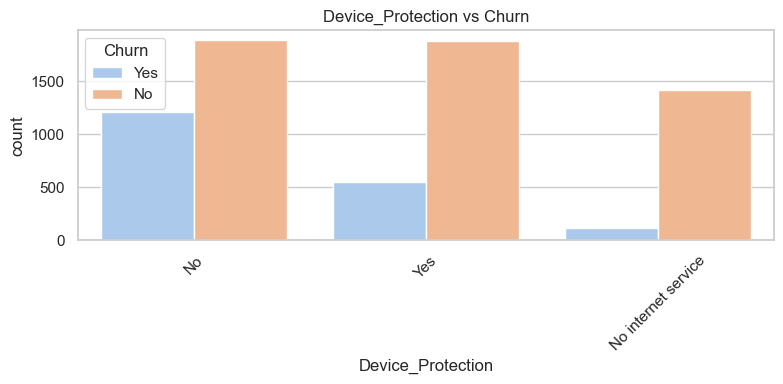

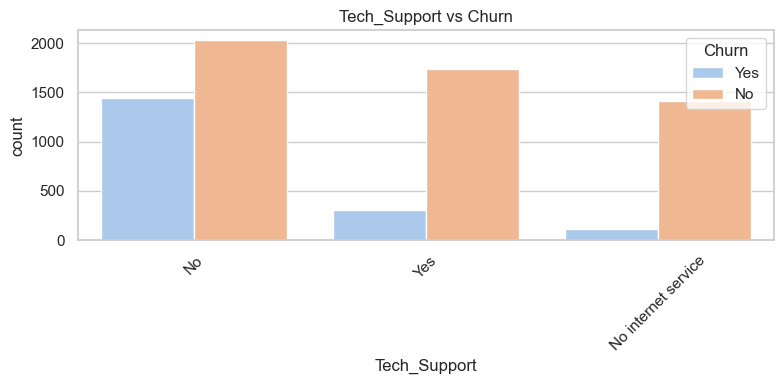

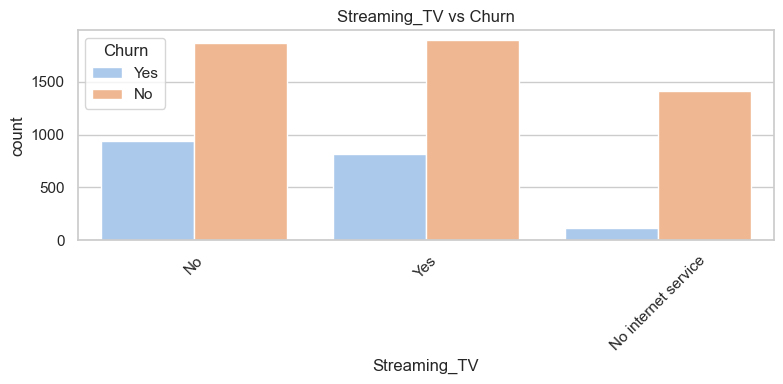

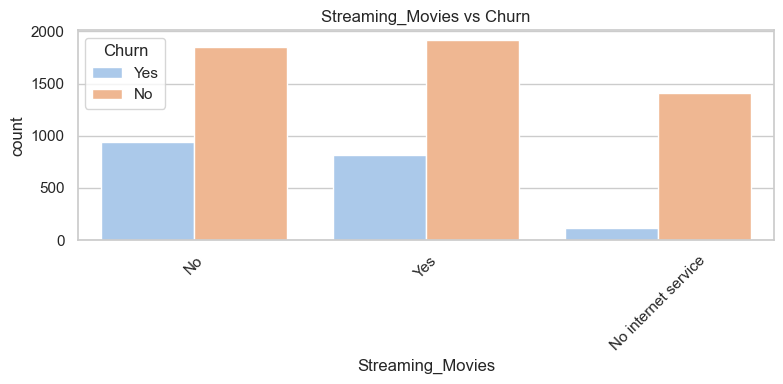

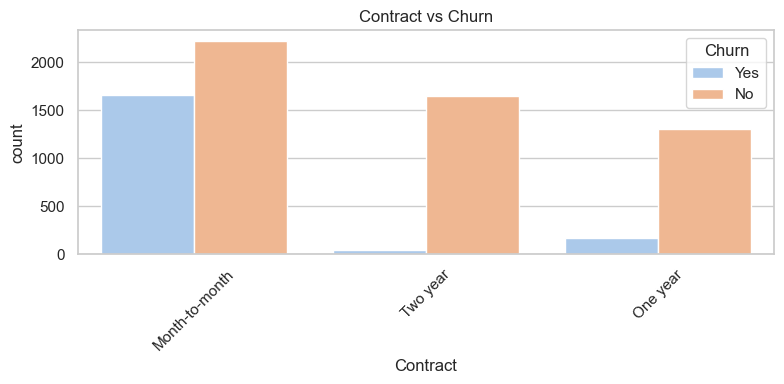

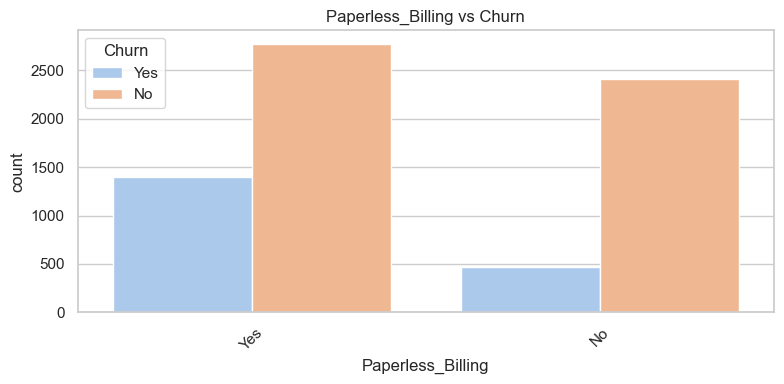

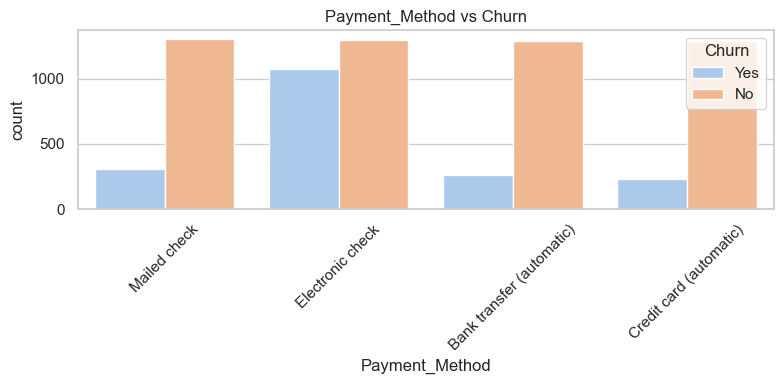

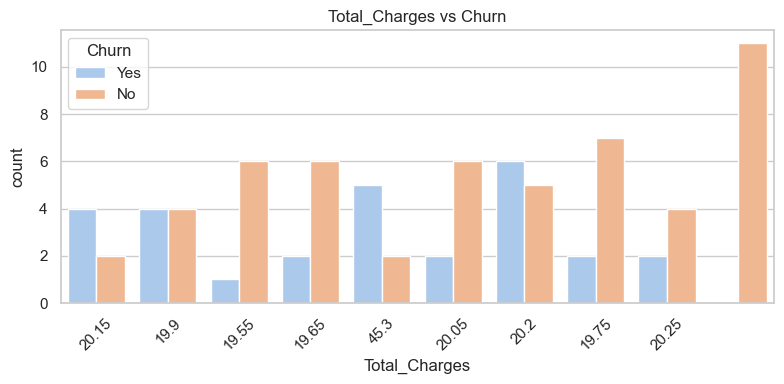

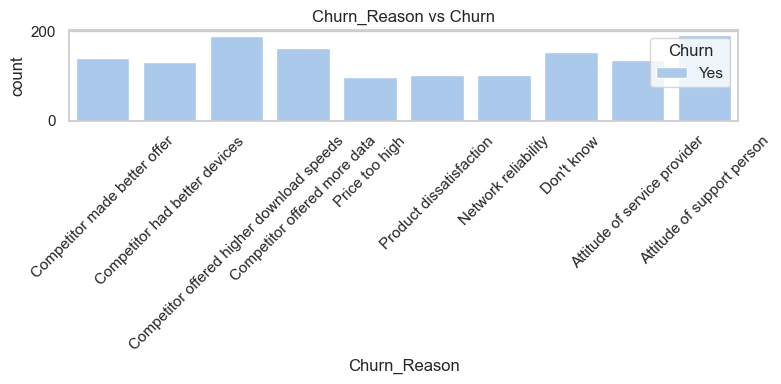


Таблица сопряженности Country и Churn (доля ушедших):
Churn_Label      No   Yes
Country                  
United States  0.73  0.27

Таблица сопряженности State и Churn (доля ушедших):
Churn_Label    No   Yes
State                  
California   0.73  0.27

Таблица сопряженности Gender и Churn (доля ушедших):
Churn_Label    No   Yes
Gender                 
Female       0.73  0.27
Male         0.74  0.26

Таблица сопряженности Senior_Citizen и Churn (доля ушедших):
Churn_Label       No   Yes
Senior_Citizen            
No              0.76  0.24
Yes             0.58  0.42

Таблица сопряженности Partner и Churn (доля ушедших):
Churn_Label    No   Yes
Partner                
No           0.67  0.33
Yes          0.80  0.20

Таблица сопряженности Dependents и Churn (доля ушедших):
Churn_Label    No   Yes
Dependents             
No           0.67  0.33
Yes          0.93  0.07

Таблица сопряженности Phone_Service и Churn (доля ушедших):
Churn_Label      No   Yes
Phone_Service            
No  

In [52]:
# Чистим названия колонок: убираем пробелы, приводим к нижнему регистру
df.columns = [col.strip().replace(" ", "_") for col in df.columns]
df.head(2)


# Список категориальных признаков (исключаем идентификаторы и target)
exclude_cols = ['CustomerID', 'Lat_Long', 'Churn_Label', 'City', 'Zip_Code']
cat_cols = [col for col in df.select_dtypes(include='object').columns if col not in exclude_cols]

print("Категориальные признаки для анализа:", cat_cols)

# Визуализация распределения по Churn
for col in cat_cols:
    plt.figure(figsize=(8,4))
    if df[col].nunique() > 10:  # топ-10 категорий для графика
        top_categories = df[col].value_counts().nlargest(10).index
        sns.countplot(data=df[df[col].isin(top_categories)], x=col, hue='Churn_Label', palette='pastel')
    else:
        sns.countplot(data=df, x=col, hue='Churn_Label', palette='pastel')
    plt.title(f"{col} vs Churn")
    plt.xticks(rotation=45)
    plt.legend(title='Churn')
    plt.tight_layout()
    plt.show()

# Таблицы сопряженности
for col in cat_cols:
    print(f"\nТаблица сопряженности {col} и Churn (доля ушедших):")
    table = pd.crosstab(df[col], df['Churn_Label'], normalize='index')
    print(table.round(2))

### Интерпретация категориальных признаков

Из 7043 клиентов ушли 26.5%, остались 73.5%.

**Демография**
- Пожилые клиенты уходят чаще: Senior_Citizen — 41.7% против 23.6% у остальных.
- Отсутствие партнера или детей повышает риск ухода: без партнера 33%, без детей 32.6%.
- Различия по полу почти нет: Female 26.9%, Male 26.2%.

**Сервисы**
- Клиенты с Fiber optic уходят чаще: 41.9%, DSL 19%, без интернета 7.4%.
- Отсутствие Online_Security, Online_Backup, Device_Protection, Tech_Support повышает уход до 40%.
- Streaming TV и Movies влияют меньше, около 30-33%.

**Контракт и биллинг**
- Month-to-month 42.7% уходят, One year 11.3%, Two year 2.8%.
- Paperless_Billing повышает уход: да — 33.6%, нет — 16.3%.

**Методы оплаты**
- Electronic check — 45.3% уходят, банковские переводы и карты — 15-17%.

**Churn_Reason**
- Все клиенты с заполненной причиной ушли, подтверждает целевую метку.

**Вывод**
- Долгосрочные контракты и дополнительные сервисы помогают удерживать клиентов.
- Нужно следить за способами оплаты и сервисами для уменьшения ухода.
- В будущем полезно объединять редкие категории в категориальных признаках, чтобы модели работали стабильнее.

Анализ числовых признаков


Числовые признаки для анализа: ['Zip_Code', 'Latitude', 'Longitude', 'Tenure_Months', 'Monthly_Charges']


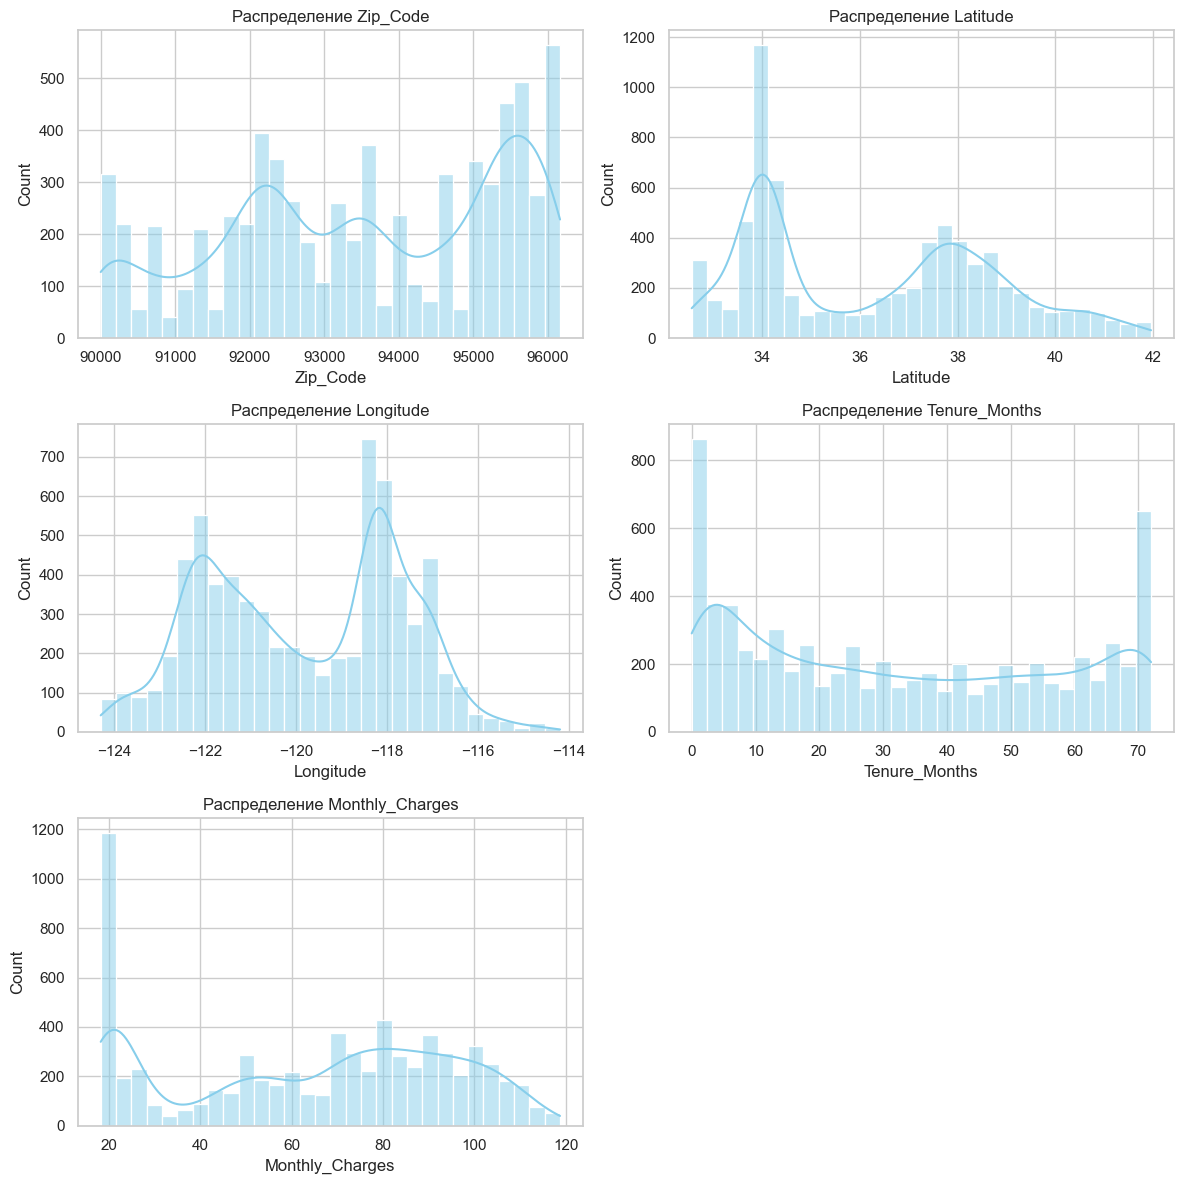

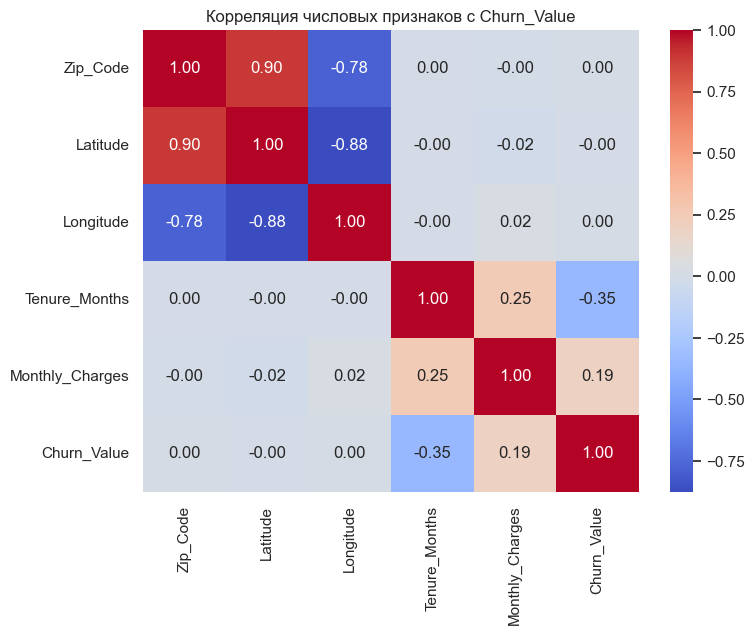

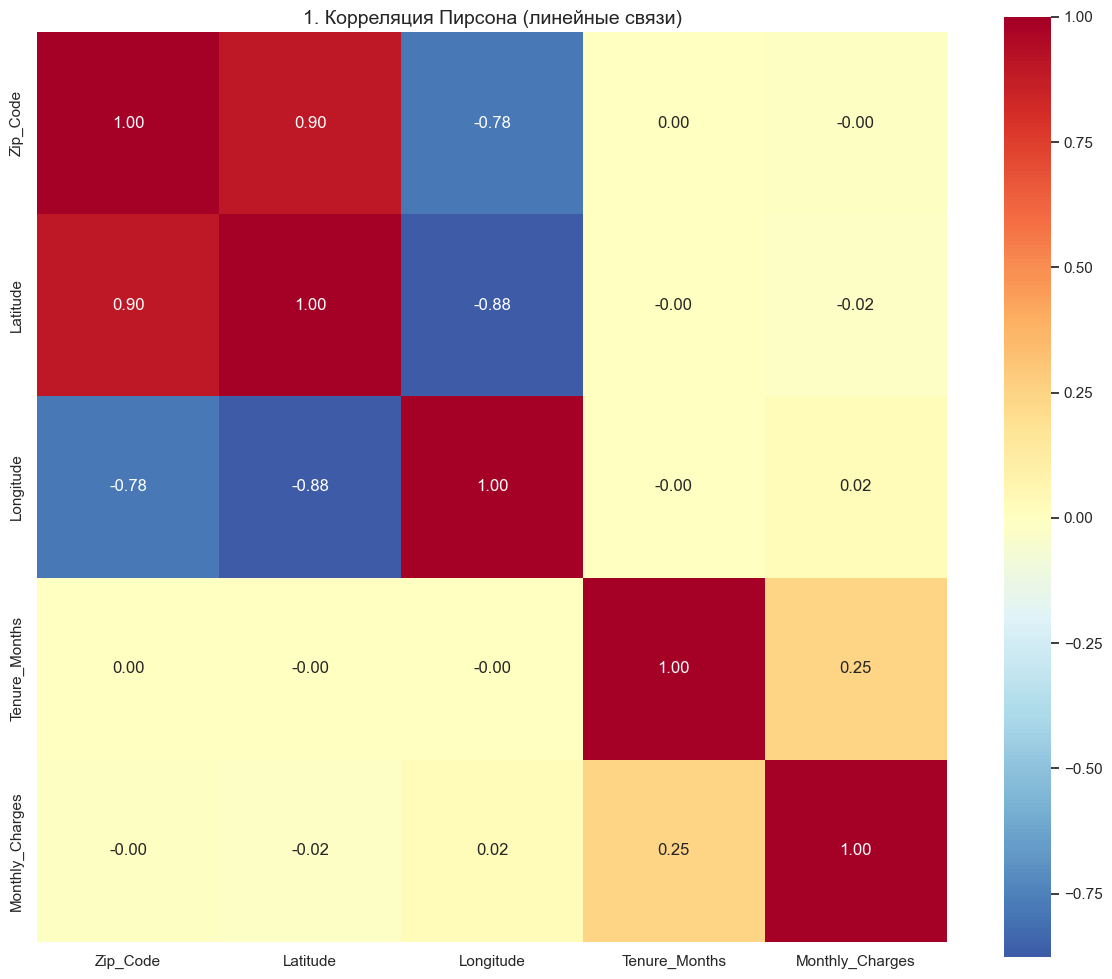

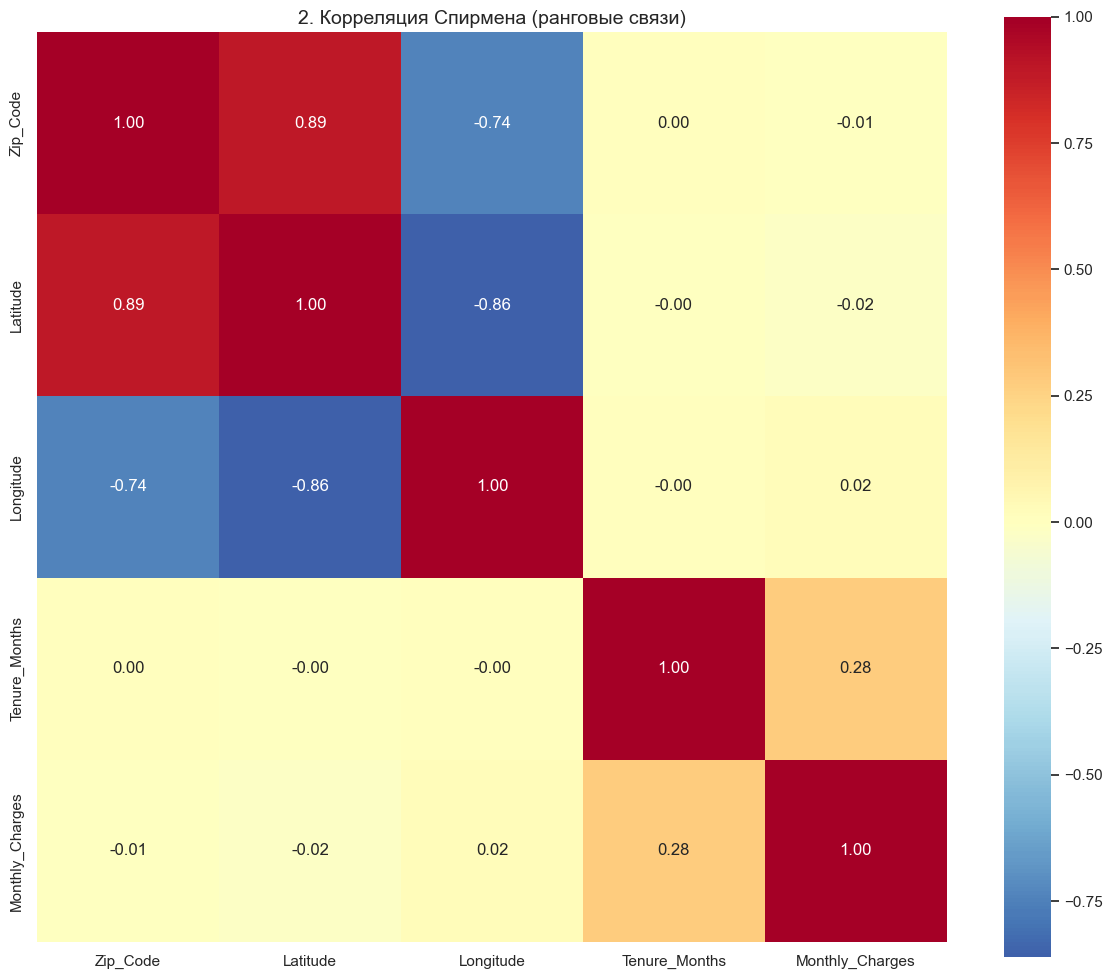

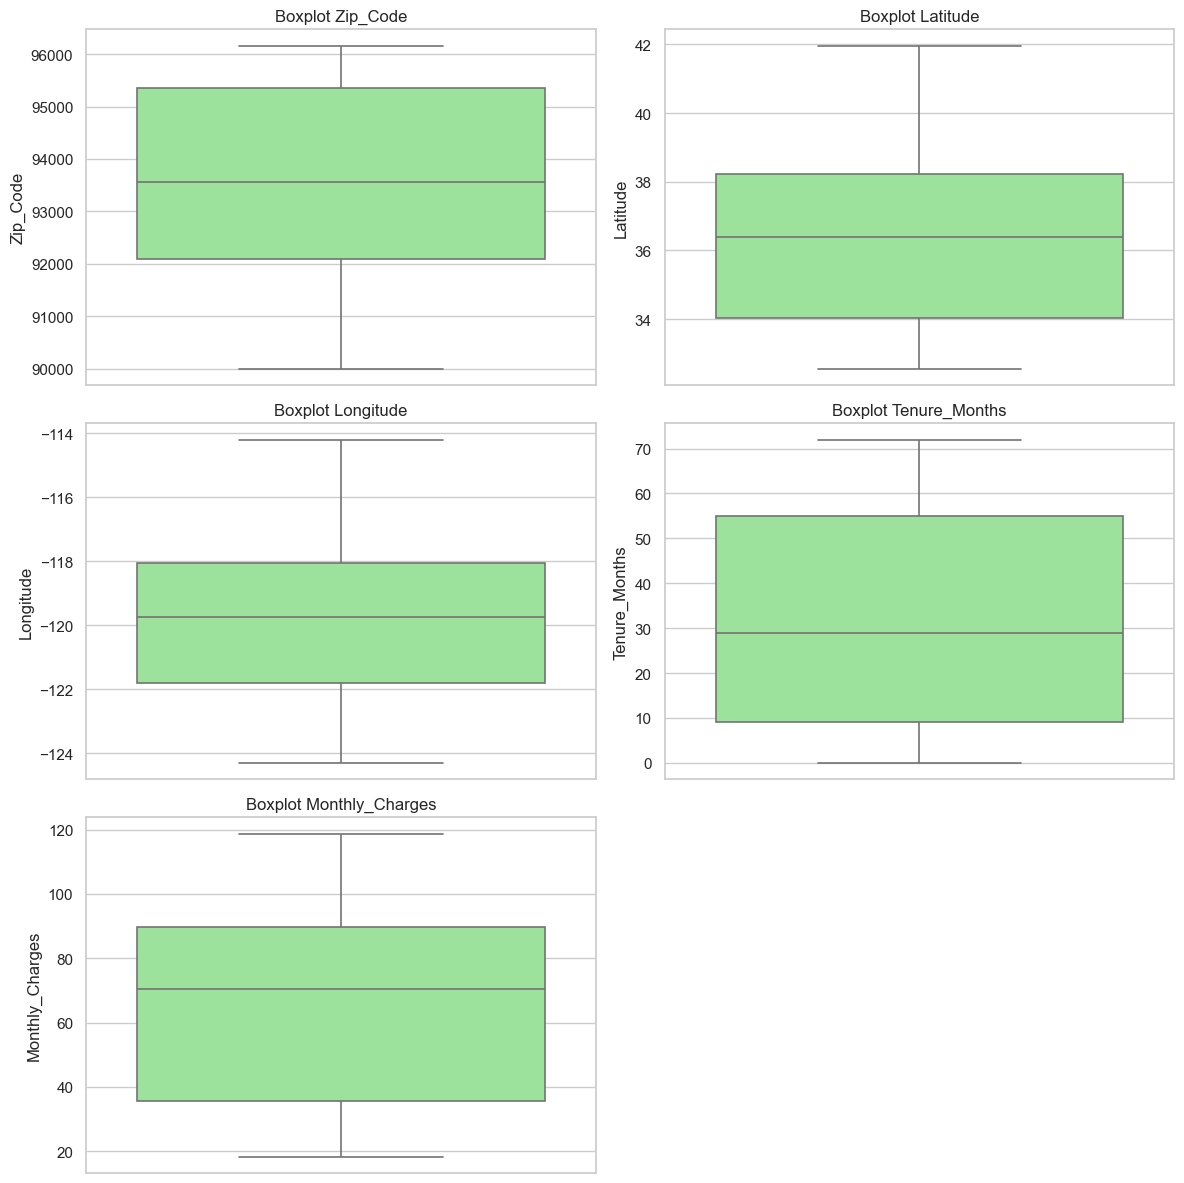


В признаке 'Zip_Code' выбросов не обнаружено

В признаке 'Latitude' выбросов не обнаружено

В признаке 'Longitude' выбросов не обнаружено

В признаке 'Tenure_Months' выбросов не обнаружено

В признаке 'Monthly_Charges' выбросов не обнаружено


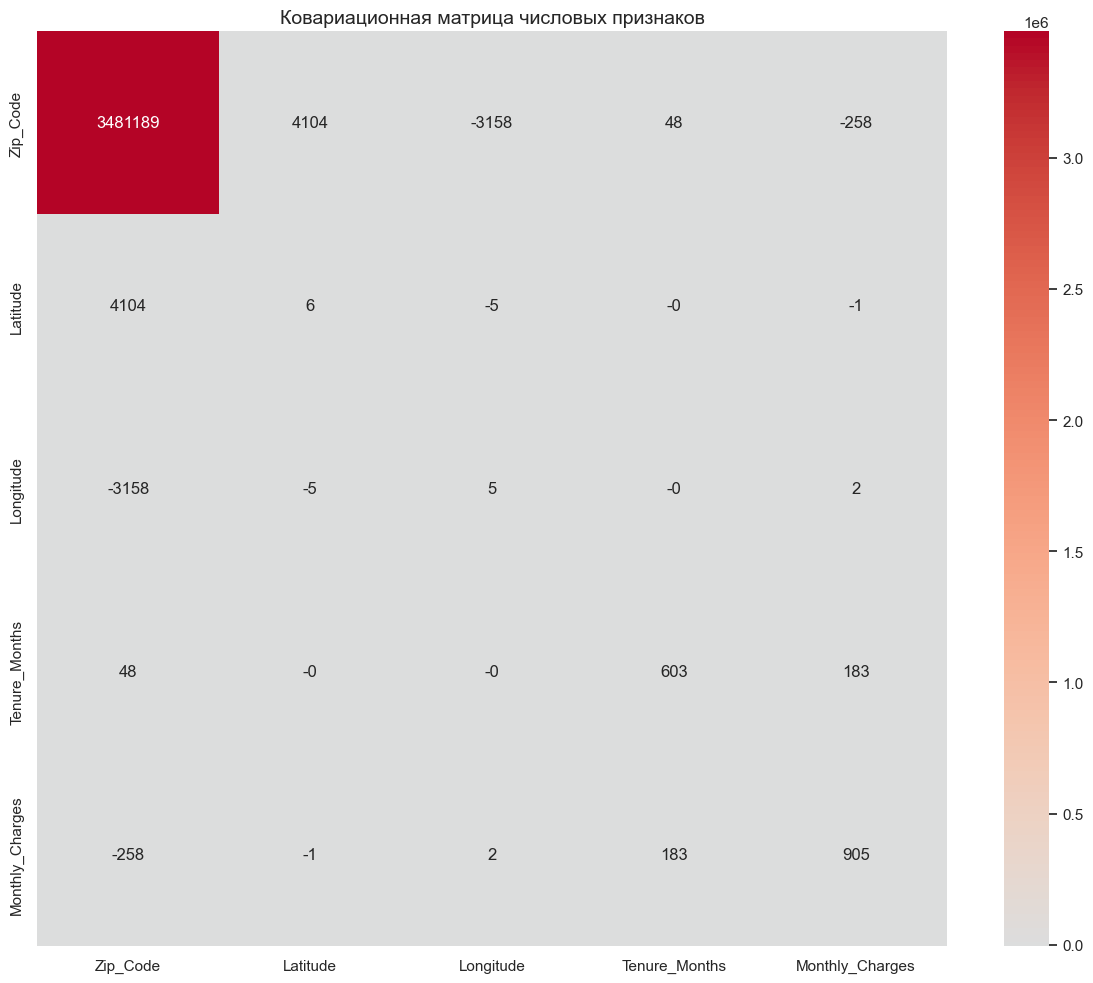

In [53]:
import matplotlib.pyplot as plt
import seaborn as sns
import math

num_cols = df.select_dtypes(include=['int64', 'float64']).drop(
    columns=['Count', 'Churn_Value', 'Churn_Score', 'CLTV'], errors='ignore'
)

print("Числовые признаки для анализа:", num_cols.columns.tolist())

df['Total_Charges'] = pd.to_numeric(df['Total_Charges'], errors='coerce')
# Заполни пропуски нулями, так как это новые клиенты
df['Total_Charges'] = df['Total_Charges'].fillna(0)

cols_to_drop = ['CustomerID', 'Count', 'Country', 'State']
df.drop(columns=cols_to_drop, inplace=True, errors='ignore')
# Гистограммы с KDE
n_cols = 2
n_rows = math.ceil(len(num_cols.columns) / n_cols)
plt.figure(figsize=(n_cols * 6, n_rows * 4))

for i, col in enumerate(num_cols.columns, 1):
    plt.subplot(n_rows, n_cols, i)
    sns.histplot(df[col], kde=True, color='skyblue', bins=30)
    plt.title(f'Распределение {col}')

plt.tight_layout()
plt.show()

# Корреляция с целевой переменной
plt.figure(figsize=(8, 6))
corr_cols = num_cols.columns.tolist() + ['Churn_Value']
sns.heatmap(df[corr_cols].corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Корреляция числовых признаков с Churn_Value')
plt.show()

# 1. Корреляция Пирсона (для линейных связей)
plt.figure(figsize=(12, 10))
sns.heatmap(num_cols.corr(method='pearson'), annot=True, fmt='.2f',
            cmap="RdYlBu_r", center=0, square=True)
plt.title("1. Корреляция Пирсона (линейные связи)", fontsize=14)
plt.tight_layout()
plt.show()

# 2. Корреляция Спирмена (ранговая, для монотонных связей)
plt.figure(figsize=(12, 10))
sns.heatmap(num_cols.corr(method='spearman'), annot=True, fmt='.2f',
            cmap="RdYlBu_r", center=0, square=True)
plt.title("2. Корреляция Спирмена (ранговые связи)", fontsize=14)
plt.tight_layout()
plt.show()



# Boxplot
plt.figure(figsize=(n_cols * 6, n_rows * 4))
for i, col in enumerate(num_cols.columns, 1):
    plt.subplot(n_rows, n_cols, i)
    sns.boxplot(
        y=df[col],
        color='lightgreen',
        showfliers=True,
        fliersize=5,
        linewidth=1.2
    )
    plt.title(f'Boxplot {col}')
plt.tight_layout()
plt.show()

for col in num_cols.columns:
    stats = boxplot_stats(df[col].dropna())
    if stats:
        outliers = stats[0]["fliers"]
        if len(outliers) > 0:
            print(f"\nВыбросы в признаке '{col}':")
            print(f"  Количество выбросов: {len(outliers)}")
            print(f"  Примеры значений: {outliers[:5]}")
            print(f"  Диапазон значений (мин-макс): {df[col].min():.2f} - {df[col].max():.2f}")
        else:
            print(f"\nВ признаке '{col}' выбросов не обнаружено")

# Ковариационная матрица
cov_matrix = df[num_cols.columns].cov()

# Визуализация ковариационной матрицы
plt.figure(figsize=(12, 10))
sns.heatmap(cov_matrix, annot=True, fmt='.0f', cmap='coolwarm', center=0)
plt.title("Ковариационная матрица числовых признаков", fontsize=14)
plt.tight_layout()
plt.show()


# Анализ числовых признаков

## 1. Корреляция
- **Zip_Code** и **Latitude** сильно положительно коррелируют между собой.
- **Longitude** отрицательно коррелирует с **Zip_Code** и **Latitude**.
- **Tenure_Months** показывает отрицательную корреляцию с **Churn_Value** (-0.35), а **Monthly_Charges** положительную (0.19).

**Вывод:** срок обслуживания и ежемесячная плата могут быть полезными признаками для предсказания оттока клиентов.

## 2. Boxplot и распределение
- **Tenure_Months**: широкий разброс значений, медиана около 25–30 месяцев. Много новых клиентов и много клиентов с длительным стажем, средние значения встречаются реже.
- **Monthly_Charges**: распределение с длинным хвостом вверх, несколько клиентов платят значительно больше остальных.
- **Latitude** и **Longitude**: распределения с несколькими пиками, что указывает на географические кластеры клиентов.
- **Zip_Code**: многомодальное распределение, отражает адресные кластеры, анализировать как числовой признак не всегда корректно.

## 3. Общие наблюдения
- Данные показывают сильную региональную сегментацию клиентов.
- **Tenure_Months** и **Monthly_Charges** особенно важны для модели, их стоит использовать.
- **Zip_Code**, **Latitude** и **Longitude** лучше использовать после группировки или как категориальные/кластерные признаки.
- Необходимо проверить и при необходимости обработать выбросы по **Monthly_Charges** и **Tenure_Months**.

PCA анализ

Признаки для PCA (чистые): ['Tenure_Months', 'Monthly_Charges', 'Total_Charges']


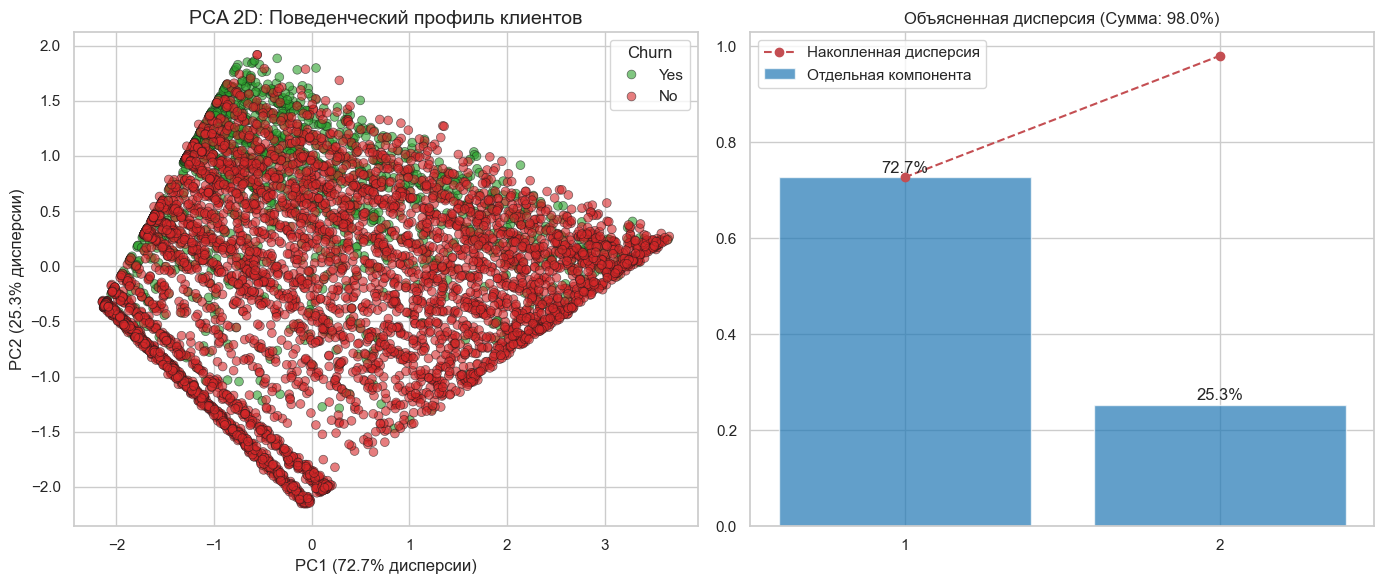


Вклад признаков в компоненты:
                      PC1       PC2
Tenure_Months    0.567299 -0.606784
Monthly_Charges  0.485842  0.792495
Total_Charges    0.664928 -0.061360


In [55]:

import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# 1. Подготовка признаков
# Убеждаемся, что Total_Charges — число, и берем только поведенческие метрики
df['Total_Charges'] = pd.to_numeric(df['Total_Charges'], errors='coerce').fillna(0)
features_for_pca = ['Tenure_Months', 'Monthly_Charges', 'Total_Charges']

print(f"Признаки для PCA (чистые): {features_for_pca}")

# 2. Масштабирование
scaler = StandardScaler()
df_scaled = scaler.fit_transform(df[features_for_pca])

# 3. Обучение PCA
pca_2d = PCA(n_components=2)
pca_coords_2d = pca_2d.fit_transform(df_scaled)

# 4. Визуализация
plt.figure(figsize=(14,6))

# Левый график: Scatter
plt.subplot(1, 2, 1)
sns.scatterplot(
    x=pca_coords_2d[:,0],
    y=pca_coords_2d[:,1],
    hue=df['Churn_Label'],
    palette=['#2ca02c', '#d62728'],
    alpha=0.6,
    s=40,
    edgecolor='k'
)
plt.xlabel(f'PC1 ({pca_2d.explained_variance_ratio_[0]:.1%} дисперсии)')
plt.ylabel(f'PC2 ({pca_2d.explained_variance_ratio_[1]:.1%} дисперсии)')
plt.title('PCA 2D: Поведенческий профиль клиентов', fontsize=14)
plt.legend(title='Churn', loc='best')

# Правый график: Дисперсия
plt.subplot(1, 2, 2)
var_ratio = pca_2d.explained_variance_ratio_
plt.bar([1, 2], var_ratio, alpha=0.7, color='#1f77b4', label='Отдельная компонента')
plt.plot([1, 2], np.cumsum(var_ratio), 'ro--', label='Накопленная дисперсия')
for i, v in enumerate(var_ratio):
    plt.text(i+1, v + 0.01, f"{v:.1%}", ha='center')
plt.xticks([1, 2])
plt.title(f'Объясненная дисперсия (Сумма: {var_ratio.sum():.1%})')
plt.legend()

plt.tight_layout()
plt.show()

# 5. Анализ вкладов (Loadings)
loadings = pd.DataFrame(
    pca_2d.components_.T,
    columns=['PC1', 'PC2'],
    index=features_for_pca
)
print("\nВклад признаков в компоненты:")
print(loadings)


## Вывод по PCA (отток клиентов)

Проведённый анализ методом главных компонент показал следующее:


### 1. Информативность компонент
Две первые компоненты объясняют около 98% дисперсии.
Это означает, что поведение клиента (срок обслуживания и платежи) практически полностью описывается в двумерном пространстве, а потеря информации минимальна.

### 2. Интерпретация компонент
- **PC1 (72.7%) — жизненный цикл клиента**
  Отражает накопленную ценность: чем выше значение, тем дольше клиент пользуется услугами и тем больше его суммарные платежи (Total_Charges).

- **PC2 (25.3%) — тарифная нагрузка**
  Разделяет клиентов по уровню ежемесячных платежей (Monthly_Charges).

### 3. Геометрия данных
После удаления лишних признаков исчезла «слоистость» данных.
Текущая форма распределения напоминает «веер» и объясняется зависимостью между стажем клиента и его платежами.
Ранее наблюдаемые искажения были вызваны признаком Zip_Code.

### 4. Распределение классов (Churn)
- Ушедшие клиенты концентрируются в области с высоким Monthly_Charges и низким Tenure.
- Это сегмент «дорогих новых клиентов», который наиболее подвержен оттоку.
- При этом классы остаются сильно перемешанными, что не позволяет эффективно разделить их линейной моделью.

### 5. Выводы для моделирования
- Высокая объяснённая дисперсия указывает на мультиколлинеарность между Tenure, Monthly_Charges и Total_Charges.
- Для решения задачи важны нелинейные зависимости.
- Наиболее подходящие модели — ансамбли деревьев (Random Forest, XGBoost, CatBoost).

# Итоговое заключение по EDA
**Проект:** Детектор оттока клиентов (Telco Customer Churn)
**Выполнил:** Садовников Олег Юрьевич

## 1. Постановка задачи
- **Бизнес-цель:** Снижение финансовых потерь за счет выявления потенциально уходящих клиентов.
- **ML-задача:** Бинарная классификация (Churn: Yes / No).
- **Метрики:** Recall для выявления всех уходящих, F1-score для баланса точности и полноты при дисбалансе классов.

## 2. Основные инсайты
- **Тип контракта:** помесячная оплата — высокий отток (≈43%), долгосрочные контракты — низкий (≈3–11%).
- **Интернет:** Fiber optic — высокий отток (≈42%), DSL и отсутствие интернета — низкий.
- **Дополнительные услуги:** Tech Support, Online Backup и Device Protection повышают лояльность.
- **Финансы и стаж:** ключевые числовые признаки — Tenure_Months и Monthly_Charges.
- **Демография:** Senior_Citizen и отсутствие партнера или детей увеличивают риск ухода.

## 3. Рекомендации для моделирования
- **Признаки:** удалить CustomerID и Count; преобразовать Total_Charges в числовой формат.
- **Геоданные:** Zip_Code и координаты лучше использовать через кластеризацию или Target Encoding.
- **Алгоритмы:** линейные модели могут быть недостаточно эффективны; предпочтительны ансамбли деревьев (Random Forest, CatBoost, XGBoost).
- **Дисбаланс:** использовать class_weight для корректного обучения.